<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/earth-data/index.html">Earth Data in Python and R</a><span class="sep">·</span>Part 2 · Gridded data with xarray</p><p class="mh-facts"><span class="lvl lvl-introductory">Introductory</span></p><p class="mh-assumes">Some programming in any language.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Gridded Earth data arrive as blocks of numbers, and a block of numbers cannot tell you which axis is latitude, which row is 30°N or whether the values are in kelvin. xarray stores those facts next to the numbers: each axis has a **name** (a dimension), each position along it a **label** (a coordinate), and each variable **metadata** (attributes). This module builds a small synthetic Dataset of monthly near-surface air temperature and shows what the labels buy. Selection by label replaces index arithmetic; arithmetic lines arrays up by dimension name, so a transposed array subtracts correctly where NumPy refuses; reductions name the dimension they remove. The attributes follow the Climate and Forecast (CF) conventions and survive a NetCDF round trip, but xarray does not check them, so an operation can carry a unit that is no longer true. Afterwards you should be able to read an xarray repr, select by label and by position, write arithmetic that does not depend on axis order, and keep attributes honest.
:::

In [1]:
import sys
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# fallcolor is the site's colour module at the repo root, not an installed package.
sys.path.insert(
    0,
    str(
        next(
            p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "fallcolor.py").exists()
        )
    ),
)
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
warnings.formatwarning = lambda msg, cat, *_, **__: (
    f"{cat.__name__}: {msg}\n"
)  # no file paths in output
xr.set_options(display_style="text")  # plain-text reprs keep the page short
print("xarray", xr.__version__)

xarray 2026.7.0


## Names, labels and metadata

Start with a plain NumPy array: two years of monthly temperature on a coarse latitude–longitude grid, built from a pole-to-equator gradient, a seasonal cycle of opposite sign in each hemisphere, and seeded noise.

In [2]:
rng = np.random.default_rng(2026)
lat = np.arange(-75.0, 76.0, 15.0)  # cell centres, degrees north
lon = np.arange(0.0, 360.0, 30.0)  # cell centres, degrees east
time = pd.date_range("2020-01-01", periods=24, freq="MS")  # first of each month
phase = np.cos(2 * np.pi * (time.month.to_numpy() - 1) / 12)  # +1 in January
mean_state = 300.0 - 45.0 * np.sin(np.radians(lat)) ** 2  # K
seasonal = -12.0 * np.sin(np.radians(lat))  # K; north is cold in January
noise = rng.normal(0.0, 1.5, (time.size, lat.size, lon.size))  # K
values = (
    mean_state[None, :, None] + seasonal[None, :, None] * phase[:, None, None] + noise
)
print(values.shape)
print(round(values[0, 0, 0], 1))

(24, 11, 12)
268.4


`(24, 11, 12)` and `268.4`. Nothing in the array says that the first axis is time, that row 0 is 75°S rather than 75°N, or that 268.4 is in kelvin. Every later line that writes `values[:, 3, :]` has to remember it. An `xarray.Dataset` stores it with the numbers: a name for each axis, a coordinate array of labels for each name, and attributes on the variable, the coordinates and the Dataset as a whole:

In [3]:
tas_attrs = {
    "standard_name": "air_temperature",
    "long_name": "Near-surface air temperature",
    "units": "K",
}
ds = xr.Dataset(
    data_vars={"tas": (("time", "lat", "lon"), values, tas_attrs)},
    coords={
        "time": time,
        "lat": ("lat", lat, {"standard_name": "latitude", "units": "degrees_north"}),
        "lon": ("lon", lon, {"standard_name": "longitude", "units": "degrees_east"}),
    },
    attrs={"title": "Synthetic monthly temperature", "source": "seeded random numbers"},
)
ds

<xarray.Dataset> Size: 26kB
Dimensions:  (time: 24, lat: 11, lon: 12)
Coordinates:
  * time     (time) datetime64[us] 192B 2020-01-01 2020-02-01 ... 2021-12-01
  * lat      (lat) float64 88B -75.0 -60.0 -45.0 -30.0 ... 30.0 45.0 60.0 75.0
  * lon      (lon) float64 96B 0.0 30.0 60.0 90.0 ... 240.0 270.0 300.0 330.0
Data variables:
    tas      (time, lat, lon) float64 25kB 268.4 270.0 266.8 ... 246.8 249.0
Attributes:
    title:    Synthetic monthly temperature
    source:   seeded random numbers

Read the repr from the top:

- **Dimensions** are the axis names and their lengths.
- **Coordinates** are the labels. `*` marks a dimension's index, the coordinate `.sel` looks labels up in.
- **Data variables** are the measured quantities; `tas (time, lat, lon)` lists the dimensions it spans, in order.
- **Attributes** here are the Dataset's *global* metadata; each variable and coordinate has its own.

One variable on its own is a `DataArray`, with its dimensions, coordinates and attributes.

In [4]:
tas = ds["tas"]  # ds.tas is the same thing
print(type(tas).__name__, tas.dims, tas.shape)
print(tas.attrs)

DataArray ('time', 'lat', 'lon') (24, 11, 12)
{'standard_name': 'air_temperature', 'long_name': 'Near-surface air temperature', 'units': 'K'}


## Selecting by label or by position

`.sel` selects by coordinate label; `.isel` selects by integer position, exactly as NumPy indexing would. They reach the same value:

In [5]:
by_label = tas.sel(time="2021-07-01", lat=45, lon=90)
by_position = tas.isel(time=18, lat=8, lon=3)
print(by_label.item(), by_position.item(), values[18, 8, 3])

288.31907825139126 288.31907825139126 288.31907825139126


The label version keeps its meaning if the file is later cropped or reordered, so prefer `.sel`. By default a label must match exactly; for a latitude the grid lacks, `.sel` raises rather than guess. `method="nearest"` takes the closest cell, and the result's coordinates say which:

In [6]:
try:
    tas.sel(lat=40)
except KeyError as err:
    print("KeyError:", err)
point = tas.sel(lat=40, lon=100, method="nearest")
print("nearest cell:", point.lat.item(), "N,", point.lon.item(), "E; dims", point.dims)

KeyError: "not all values found in index 'lat'. Try setting the `method` keyword argument (example: method='nearest')."
nearest cell: 45.0 N, 90.0 E; dims ('time',)


A `slice` selects a range of labels. A label slice **includes both ends**, unlike a position slice, and runs in the order the coordinate is stored, so on a grid stored north to south, as many reanalysis files are, the same slice returns nothing:

In [7]:
print("lat in slice(-30, 30):", tas.sel(lat=slice(-30, 30)).lat.values)
print("months in '2021':", tas.sel(time="2021").sizes["time"])
north_to_south = tas.sortby("lat", ascending=False)
print(
    "same slice, descending lat:",
    north_to_south.sel(lat=slice(-30, 30)).sizes["lat"],
    "rows",
)
print("reversed slice:", north_to_south.sel(lat=slice(30, -30)).lat.values)

lat in slice(-30, 30): [-30. -15.   0.  15.  30.]
months in '2021': 12
same slice, descending lat: 0 rows
reversed slice: [ 30.  15.   0. -15. -30.]


Inclusive ends are why [Scaling a NetCDF subset](../partial-scaling-netcdf/index.qmd) nudges one boundary by `1e-9`: the slices `slice(-30, 90)` and `slice(-90, -30)` would both contain a row at exactly 30°S. Check `lat[0]` and `lat[-1]` of an unfamiliar file before slicing it.

## Operations follow dimension names

NumPy combines arrays by axis position; xarray combines them by dimension name. Take one month and a copy transposed to `(lon, lat)`:

In [8]:
jan = tas.sel(time="2021-01-01")
jan_t = jan.transpose("lon", "lat")
try:
    jan.values - jan_t.values
except ValueError as err:
    print("NumPy:", err)
difference = jan - jan_t
print("xarray:", difference.dims, "max |difference| =", float(abs(difference).max()))

NumPy: operands could not be broadcast together with shapes (11,12) (12,11) 
xarray: ('lat', 'lon') max |difference| = 0.0


NumPy refuses because shapes (11, 12) and (12, 11) do not line up. Had the grid been square it would have subtracted latitude from longitude without complaint. xarray matches `lat` with `lat` and `lon` with `lon`, and the difference is exactly zero.

The same rule gives **broadcasting by name**: an array lacking a dimension is repeated along it. Latitude weights multiply the full field without `[None, :, None]` reshaping, and a condition on `lat` applies to every month and longitude:

In [9]:
weights = np.cos(
    np.deg2rad(ds["lat"])
)  # grid-cell area is proportional to cos(latitude)
print("weights", weights.dims, "x tas", tas.dims, "->", (tas * weights).dims)
south_halved = tas.where(
    tas["lat"] >= -30, tas * 0.5
)  # keep where True, else use the second argument
print("cells changed:", int((south_halved != tas).sum()), "of", tas.size)

weights ('lat',) x tas ('time', 'lat', 'lon') -> ('time', 'lat', 'lon')
cells changed: 864 of 3168


Three latitude rows (75°S, 60°S, 45°S) times 12 longitudes times 24 months is 864 cells. Before combining, xarray also aligns operands on their labels; where labels differ, the default keeps only those both share, an inner join:

In [10]:
north = tas.sel(lat=slice(0, 90))
print(
    "tas lat:",
    tas.sizes["lat"],
    "| north lat:",
    north.sizes["lat"],
    "| tas - north lat:",
    (tas - north).sizes["lat"],
)

tas lat: 11 | north lat: 6 | tas - north lat: 6


No error and no NaNs: the southern rows simply disappear. The same shrinkage is the symptom when two grids differ by a rounding error in their coordinates.

**Reductions** take the dimension to remove by name. The time mean is `tas.mean("time")`, and an area-weighted global mean names the two spatial dimensions:

In [11]:
climatology = tas.mean("time")
print("climatology dims:", climatology.dims)
global_weighted = climatology.weighted(weights).mean(("lat", "lon"))
global_plain = climatology.mean(("lat", "lon"))
print(f"global mean, cos-latitude weighted: {global_weighted.item():.1f} K")
print(f"global mean, unweighted:            {global_plain.item():.1f} K")

climatology dims: ('lat', 'lon')
global mean, cos-latitude weighted: 285.1 K
global mean, unweighted:            279.5 K


The unweighted mean counts a small polar cell as much as an equatorial one, so it comes out colder. Plotting is driven by the labels too: `.plot()` builds axis and colour-bar labels from `long_name` (or `standard_name`) and `units`:

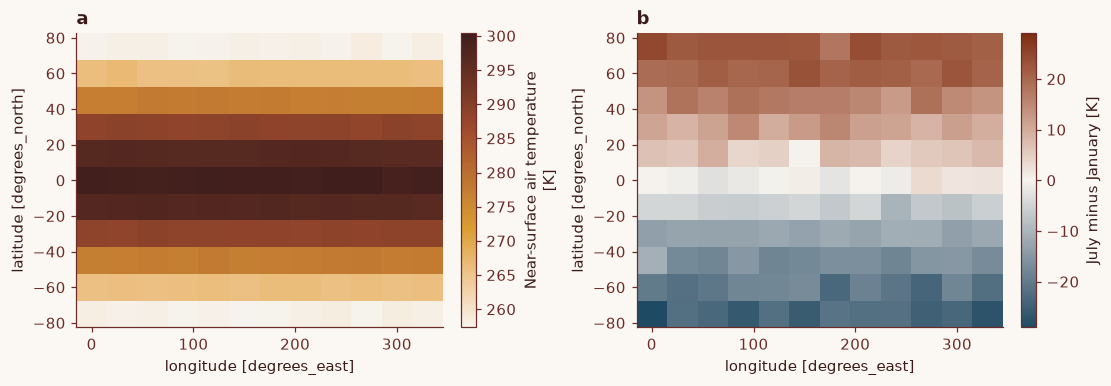

In [12]:
seasonal_range = tas.sel(time="2021-07-01") - tas.sel(time="2021-01-01")
seasonal_range.attrs = {
    "long_name": "July minus January",
    "units": "K",
}  # see the next section
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
climatology.plot(ax=axes[0], cmap="fall.ember")
seasonal_range.plot(
    ax=axes[1], cmap="fall.tide", norm=fallcolor.palette.centered(seasonal_range)
)
for ax, letter in zip(axes, "ab"):
    ax.set_title(letter, loc="left", fontweight="bold")
plt.show()

<strong>Figure 1 | Labels and attributes are enough for xarray to draw a correctly labelled map.</strong>
<strong>a</strong>, Two-year mean near-surface air temperature (K), `tas.mean("time")`. <strong>b</strong>, July 2021 minus January 2021 (K), diverging scale centred on zero: warmer in July in the north, colder in the south. All axis and colour-bar labels come from attributes; the 15° by 30° cells are the grid.

## Attributes and the CF conventions

Attributes are a plain dictionary; xarray puts no rules on them. The rules come from the **Climate and Forecast (CF) metadata conventions**[^1], widely used for climate and weather NetCDF files:

- `units` is a unit string a units library can parse (`K`, `degrees_north`, `kg m-2 s-1`).
- `standard_name` comes from the CF standard name table, so `air_temperature` means the same quantity in every file, whatever the variable is called.
- `long_name` is a free-text description for people and plots.

### A round trip through NetCDF

Write the Dataset to NetCDF and read it back. The SciPy backend used here writes the older NetCDF3 format:

In [13]:
with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / "tas.nc"
    ds.to_netcdf(path, engine="scipy")
    with xr.open_dataset(path, engine="scipy") as back:
        back = back.load()
print("tas attrs:", back["tas"].attrs)
print("global attrs:", back.attrs)
print("time stored as:", back["time"].encoding["units"])
xr.testing.assert_identical(back, ds)
print("identical after the round trip")

tas attrs: {'standard_name': 'air_temperature', 'long_name': 'Near-surface air temperature', 'units': 'K'}
global attrs: {'title': 'Synthetic monthly temperature', 'source': 'seeded random numbers'}
time stored as: days since 2020-01-01 00:00:00
identical after the round trip


Every attribute came back, and `assert_identical`, which compares values, coordinates and attributes, passes. The times were stored as integers counting "days since" the first month, the CF way of writing time, and decoded back to datetimes on reading.

### What happens to attributes in a calculation

Attributes are lost or corrupted in calculations, not in files. Which operations keep them is a library decision that varies between versions, so check yours:

In [14]:
print("keep_attrs =", repr(xr.get_options()["keep_attrs"]))
celsius = tas - 273.15
print("tas - 273.15        units:", celsius.attrs.get("units"))
print("tas.mean('time')    units:", tas.mean("time").attrs.get("units"))
print("np.sqrt(tas)        units:", np.sqrt(tas).attrs.get("units"))
print(f"celsius values span {celsius.min().item():.1f} to {celsius.max().item():.1f}")

keep_attrs = 'default'
tas - 273.15        units: K
tas.mean('time')    units: K
np.sqrt(tas)        units: K
celsius values span -29.8 to 31.7


This release keeps attributes through arithmetic, reductions and NumPy functions. Right for the mean, wrong for the other two: `celsius` holds values from about −30 to 32 labelled kelvin. Attributes are copied, not computed, so after any operation that changes what the numbers mean, set them yourself:

In [15]:
celsius = (tas - 273.15).assign_attrs(units="degC")
print(celsius.attrs)

{'standard_name': 'air_temperature', 'long_name': 'Near-surface air temperature', 'units': 'degC'}


`standard_name` stays valid: CF gives `air_temperature` the canonical unit K and accepts any unit convertible to it. Attributes do still disappear in four situations:

In [16]:
other = tas.copy().assign_attrs(long_name="Something else")
print("conflicting operands:   ", (tas - other).attrs)
print(
    "rebuilt from .values:   ",
    xr.DataArray(tas.values, dims=tas.dims, coords=tas.coords).attrs,
)
with xr.set_options(keep_attrs=False):
    print("keep_attrs=False:       ", tas.mean("time").attrs)
halves = [tas.sel(lat=slice(-90, -31)), tas.sel(lat=slice(-30, 90))]
merged = xr.merge(halves, join="outer", compat="no_conflicts")
print("global title after merge:", merged.attrs.get("title"))

conflicting operands:    {'standard_name': 'air_temperature', 'units': 'K'}
rebuilt from .values:    {}
keep_attrs=False:        {}
global title after merge: None


Operands that disagree keep only the attributes they share. An array rebuilt from bare `.values` starts with none. `keep_attrs=False`, globally or as a method argument, discards them on purpose. And global attributes belong to the Dataset, not to any variable, so a Dataset reassembled from DataArrays, as `xr.merge` does in [Scaling a NetCDF subset](../partial-scaling-netcdf/index.qmd), has lost its `title`; that module's `ds.copy(data=...)` puts new values back inside the original Dataset instead.

## Key takeaways

- A **dimension** names an axis, a **coordinate** labels the positions along it, a **data variable** is a measured array laid out on named dimensions, and **attributes** are metadata on any of them or on the whole Dataset.
- Select by label with `.sel`; use `method="nearest"` when the label is not on the grid, and check the returned coordinates. `.isel` is for positions.
- Label slices include both ends and follow the coordinate's stored order: on a north-to-south grid, `slice(-30, 30)` is empty.
- Arithmetic matches dimensions by name and broadcasts over missing ones, so axis order stops mattering. It also aligns on labels, keeping only shared labels by default.
- Reductions name what they remove: `tas.mean("time")`, `tas.weighted(w).mean(("lat", "lon"))`.
- Follow CF for `units`, `standard_name` and `long_name`. Attributes survive a NetCDF round trip, but they are copied rather than computed: after an operation that changes the meaning of the values, set them again.

### Data and code

- **Data**: synthetic, generated in this notebook from a seeded random number generator; no download.
- **Software**: [xarray](https://docs.xarray.dev)[^2] with NumPy, pandas, matplotlib and SciPy (the NetCDF3 backend).

## References

[^1]: CF Conventions Committee. NetCDF Climate and Forecast (CF) metadata conventions. *cfconventions.org* https://cfconventions.org
[^2]: Hoyer, S. & Hamman, J. xarray: N-D labeled arrays and datasets in Python. *J. Open Res. Softw.* **5**, 10 (2017). https://doi.org/10.5334/jors.148

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/partial-scaling-netcdf/index.html"><span>Previous</span>Scaling a NetCDF subset</a><a class="mf-up" href="/series/earth-data/index.html"><span>Series</span>Earth Data in Python and R</a><a class="mf-next" href="/blogs/r-regridding/index.html"><span>Next</span>Regridding crop data for climate models</a></div>
<!-- CURRICULUM_FOOTER_END -->